# Chapter 6: The theorem for sines

Checks [chapter 6](../../book/06-the-sine.md): the four claims of the theorem for the family
`amplitude * sin(frequency * input + phase)`, the table of the chapter, and then a sine model
that learns by SGD. These are measurements of the sine case. The Lean theorem is the proof.

Run every cell, top to bottom. A failed check stops the notebook. Every random draw is seeded,
so two runs give the same numbers.

In [1]:
from common import *

import pandas as pd

use_style()

SLACK = 3e-4          # the nearest distance is measured on a polyline, not the exact curve
BOOK_TABLE = {0.25: (0.6129, 0.6672), 1: (0.3095, 0.6649), 4: (0.0928, 0.6663),
              16: (0.0338, 0.6665), 64: (0.0207, 0.6688)}          # chapter 6: nearest, vertical
generator = torch.Generator().manual_seed(6)       # one generator, used in the order of the cells

## The sine model: width and depth

The sine model is `sum over term of amplitudes[term] * sin(term * input + phases[term])`.

- **Width** is `num_terms`: the number of hidden units. Each one is a sine of the fixed integer
  frequency `term`, with a learnable amplitude and phase.
- **Depth** is one hidden layer. The model has `2 * num_terms` learnable parameters.
- More width adds higher frequencies, so in this model width buys squiggle directly. That is not
  true of the ReLU networks of chapter 8, where width adds kinks but not squiggle the way depth does.

## Claims 1 and 2: the distance is squeezed, and its average goes to zero

For labels in the band the sine sweeps, `vertical_error / sqrt(1 + (amplitude * frequency)^2)` is at
most the nearest distance, which is at most `PI / frequency`. Three amplitudes, four frequencies,
40 random points each.

In [2]:
claim_rows = []
for amplitude in (0.5, 1.0, 2.0):
    for frequency in (0.5, 2.0, 8.0, 32.0):
        slope_limit = amplitude * frequency
        nearest_values, lower_slack, upper_slack = [], [], []
        for _ in range(40):
            phase = float(torch.rand(1, generator=generator)) * TWO_PI
            curve = lambda inputs, a=amplitude, w=frequency, p=phase: evaluate_sine(a, w, p, inputs)
            point_x = float(torch.rand(1, generator=generator)) * 20 - 10
            point_y = (float(torch.rand(1, generator=generator)) * 2 - 1) * amplitude        # in the band
            vertical_error = abs(point_y - float(curve(torch.tensor([point_x]))))
            nearest = get_nearest_distance(curve, point_x, point_y, slope_limit, resolution=2e-3)
            lower_bound = vertical_error / math.sqrt(1 + slope_limit ** 2)
            upper_bound = math.pi / frequency
            nearest_values.append(nearest)
            lower_slack.append(nearest - lower_bound)
            upper_slack.append(upper_bound - nearest)
        claim_rows.append({"amplitude": amplitude, "frequency": frequency,
                           "mean_nearest": sum(nearest_values) / len(nearest_values),
                           "upper_bound": math.pi / frequency,
                           "smallest_nearest_minus_lower": min(lower_slack),
                           "smallest_upper_minus_nearest": min(upper_slack)})

report("claim 1: lower <= nearest <= pi / frequency in every case",
       all(row["smallest_nearest_minus_lower"] >= -SLACK and row["smallest_upper_minus_nearest"] >= -SLACK
           for row in claim_rows),
       f"{len(claim_rows)} settings of 40 points; smallest slacks "
       f"{min(row['smallest_nearest_minus_lower'] for row in claim_rows):.1e} and "
       f"{min(row['smallest_upper_minus_nearest'] for row in claim_rows):.1e}")
report("claim 2: the average nearest distance is at most pi / frequency",
       all(row["mean_nearest"] <= row["upper_bound"] + SLACK for row in claim_rows))
by_amplitude_one = [row["mean_nearest"] for row in claim_rows if row["amplitude"] == 1.0]
report("claim 2: the average nearest distance falls as the frequency rises (amplitude 1)",
       all(first > second for first, second in zip(by_amplitude_one, by_amplitude_one[1:])),
       " > ".join(f"{value:.3f}" for value in by_amplitude_one))

[PASS] claim 1: lower <= nearest <= pi / frequency in every case  (12 settings of 40 points; smallest slacks 1.3e-06 and 1.2e-02)
[PASS] claim 2: the average nearest distance is at most pi / frequency
[PASS] claim 2: the average nearest distance falls as the frequency rises (amplitude 1)  (0.761 > 0.316 > 0.110 > 0.033)


True

## Claim 3: the average loss at the start is the same at every frequency

For a label `y` the average over a uniform phase of `(y - amplitude * sin(angle))^2` is
`y^2 + amplitude^2 / 2`. The average over phases is taken on an equally spaced grid, so it is
nearly exact.

In [3]:
amplitude = 0.8
phases = (torch.arange(100000) + 0.5) / 100000 * TWO_PI
data = [(0.3, 0.5), (-1.2, -0.4), (2.5, 0.8), (7.0, 0.0)]          # (input, label)

loss_rows = []
for frequency in (0.25, 1.0, 4.0, 16.0, 64.0):
    losses = []
    for point_x, label in data:
        outputs = evaluate_sine(amplitude, frequency, phases, torch.tensor(point_x))
        losses.append(float(((label - outputs) ** 2).mean()))
    loss_rows.append({"frequency": frequency, "average_loss": sum(losses) / len(losses)})

expected_loss = sum(label ** 2 + amplitude ** 2 / 2 for _, label in data) / len(data)
largest_gap = max(abs(row["average_loss"] - expected_loss) for row in loss_rows)
report("claim 3: average loss is the same at every frequency, y^2 + amplitude^2 / 2",
       largest_gap < 1e-6, f"expected {expected_loss:.6f}, largest gap {largest_gap:.1e}")

[PASS] claim 3: average loss is the same at every frequency, y^2 + amplitude^2 / 2  (expected 0.582500, largest gap 1.1e-16)


True

## Claim 4: a small shift of the inputs fits any target in the band

The warp sends each input to the nearest input where the sine equals the target. It moves each
input by at most `PI / frequency`.

In [4]:
warp_rows = []
for frequency in (1.0, 4.0, 16.0, 64.0):
    phase = 0.7
    inputs = torch.rand(20000, generator=generator) * 6 - 3
    target = 0.8 * torch.sin(2.3 * inputs) * torch.cos(0.9 * inputs)
    warp = get_nearest_hit(0.8, frequency, phase, inputs, target)
    shift = float((warp - inputs).abs().max())
    fit_error = float((evaluate_sine(0.8, frequency, phase, warp) - target).abs().max())
    warp_rows.append({"frequency": frequency, "largest_shift": shift, "bound": math.pi / frequency,
                      "fit_error": fit_error})

report("claim 4: the warp moves each input at most pi / frequency and the fit is exact",
       all(row["largest_shift"] <= row["bound"] + 1e-9 and row["fit_error"] < 1e-9 for row in warp_rows),
       "largest shifts " + ", ".join(f"{row['largest_shift']:.3f}" for row in warp_rows))

[PASS] claim 4: the warp moves each input at most pi / frequency and the fit is exact  (largest shifts 1.391, 0.512, 0.160, 0.040)


True

## The table of the chapter

Sines of one amplitude with a random phase, data uniform in the square `[-1, 1]^2` (labels outside
the band included, which is why the distance has a floor). Frequency `w` means
`sin(w * PI * input + phase)`. The nearest distance is slow, so it uses 500 points per row. The
vertical error is cheap, so it uses 200000. Each row is compared with the chapter's table within five
standard errors of this run's own 500 points (the nearest column) and within 0.01 (the vertical column).

In [5]:
peak = 0.577 * math.sqrt(2)
table = []
for key, (book_nearest, book_vertical) in BOOK_TABLE.items():
    frequency = float(key)
    slope_limit = peak * frequency * math.pi
    nearest_values = []
    for _ in range(500):
        phase = float(torch.rand(1, generator=generator)) * TWO_PI
        curve = lambda inputs, w=frequency, p=phase: peak * torch.sin(w * math.pi * inputs + p)
        point_x = float(torch.rand(1, generator=generator)) * 2 - 1
        point_y = float(torch.rand(1, generator=generator)) * 2 - 1
        nearest_values.append(get_nearest_distance(curve, point_x, point_y, slope_limit,
                                                   resolution=2e-3, domain=(-1.0, 1.0)))
    sample_count = 200000
    sample_x = torch.rand(sample_count, generator=generator) * 2 - 1
    sample_y = torch.rand(sample_count, generator=generator) * 2 - 1
    sample_phase = torch.rand(sample_count, generator=generator) * TWO_PI
    vertical_mean = float((sample_y - peak * torch.sin(frequency * math.pi * sample_x + sample_phase)).abs().mean())
    nearest_se = float(torch.tensor(nearest_values).std()) / math.sqrt(len(nearest_values))
    table.append({"frequency": frequency, "nearest": sum(nearest_values) / len(nearest_values), "nearest_se": nearest_se,
                  "book_nearest": book_nearest, "vertical": vertical_mean, "book_vertical": book_vertical})

table_frame = pd.DataFrame(table)
print(table_frame.round(4).to_string(index=False))

largest_nearest_gap = float((table_frame["nearest"] - table_frame["book_nearest"]).abs().max())
largest_vertical_gap = float((table_frame["vertical"] - table_frame["book_vertical"]).abs().max())
nearest_gaps_in_errors = ((table_frame["nearest"] - table_frame["book_nearest"]).abs() / table_frame["nearest_se"])
report("the chapter's table is reproduced: nearest within 5 standard errors row by row (500 points), vertical within 0.01 (200000 points)",
       float(nearest_gaps_in_errors.max()) < 5 and largest_vertical_gap < 0.01,
       f"largest gaps {largest_nearest_gap:.4f} (nearest, {float(nearest_gaps_in_errors.max()):.1f} standard errors) "
       f"and {largest_vertical_gap:.4f} (vertical)")
fall = table[0]["nearest"] / table[-1]["nearest"]
report("the nearest distance falls about thirty times, the vertical error does not move",
       20 < fall < 45 and table_frame["vertical"].max() - table_frame["vertical"].min() < 0.02,
       f"nearest falls {fall:.0f} times")

 frequency  nearest  nearest_se  book_nearest  vertical  book_vertical
      0.25   0.6128      0.0196        0.6129    0.6653         0.6672
      1.00   0.3154      0.0098        0.3095    0.6666         0.6649
      4.00   0.0907      0.0029        0.0928    0.6643         0.6663
     16.00   0.0323      0.0017        0.0338    0.6670         0.6665
     64.00   0.0220      0.0019        0.0207    0.6673         0.6688
[PASS] the chapter's table is reproduced: nearest within 5 standard errors row by row (500 points), vertical within 0.01 (200000 points)  (largest gaps 0.0059 (nearest, 0.9 standard errors) and 0.0020 (vertical))
[PASS] the nearest distance falls about thirty times, the vertical error does not move  (nearest falls 28 times)


True

## Check yourself

The two calculations of the chapter's "check yourself" section.

In [6]:
check_inputs = torch.linspace(0, TWO_PI / 10, 801).repeat_interleave(801)
check_labels = torch.linspace(-1, 1, 801).repeat(801)
check_hits = get_nearest_hit(1.0, 10.0, 0.0, check_inputs, check_labels)
check_reach = float((check_hits - check_inputs).abs().max())
report("frequency 10: the sine needs a reach of pi / 10 = 0.31, the upper bound", abs(check_reach - 0.314) < 1e-3,
       f"measured {check_reach:.4f}")

steep_line = lambda inputs: 100.0 * inputs          # slope limit 100: the lower bound is tight on a line
steep_nearest = get_nearest_distance(steep_line, 0.0, 0.5, 100.0, resolution=1e-4, include_foot=False)
report("slope limit 100, vertical 0.5: nearest distance 0.5 / sqrt(1 + 100^2) = 0.005 on a line",
       abs(steep_nearest - 0.5 / math.sqrt(1 + 100 ** 2)) < 1e-6, f"measured {steep_nearest:.6f}")


[PASS] frequency 10: the sine needs a reach of pi / 10 = 0.31, the upper bound  (measured 0.3142)
[PASS] slope limit 100, vertical 0.5: nearest distance 0.5 / sqrt(1 + 100^2) = 0.005 on a line  (measured 0.005000)


True

## Figure: the same points on three curves

Fourteen points drawn on sines of frequency 1, 4 and 16 times pi. Blue lines run to the nearest point of the
curve and orange lines straight up or down. The titles give the mean over 250 random draws, because
fourteen points are too few for the vertical error to look steady. Written to
`book/figures/06-frequency-strip.png`.

wrote book/figures/06-frequency-strip.png


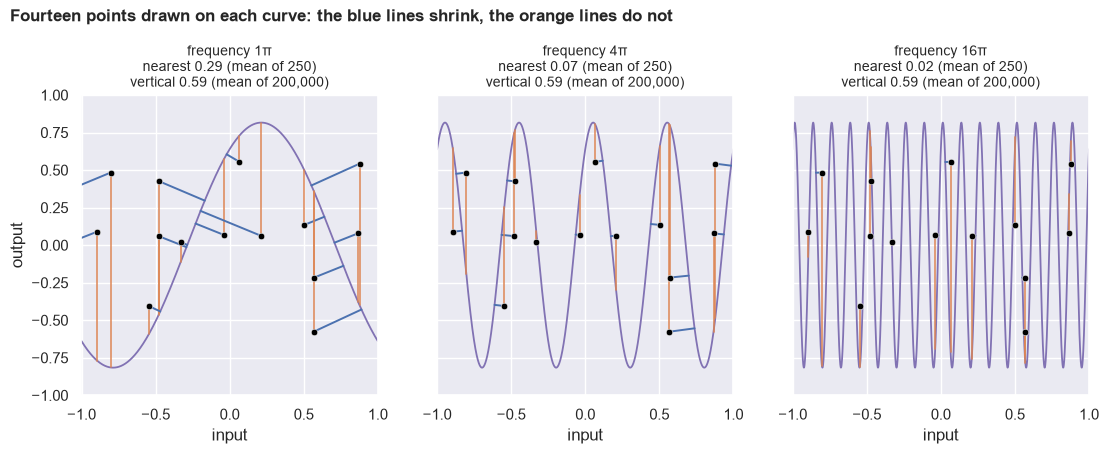

In [7]:
def get_nearest_point(curve, point_x, point_y, half_width):
    # The nearest point of the curve to the data point, by dense sampling (for drawing only).
    xs = torch.linspace(point_x - half_width, point_x + half_width, 400001)
    with torch.no_grad():
        ys = curve(xs)
    distances = (xs - point_x) ** 2 + (ys - point_y) ** 2
    best = int(distances.argmin())
    return float(xs[best]), float(ys[best]), float(distances[best].sqrt())


strip_generator = torch.Generator().manual_seed(66)
data_x = torch.rand(14, generator=strip_generator) * 1.8 - 0.9
data_y = torch.rand(14, generator=strip_generator) * 1.4 - 0.7

figure, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for axis, frequency in zip(axes, (1.0, 4.0, 16.0)):
    curve = lambda inputs, w=frequency: peak * torch.sin(w * math.pi * inputs + 0.9)
    xs = torch.linspace(-1, 1, 6000)
    sns.lineplot(x=xs.numpy(), y=curve(xs).numpy(), color=MODEL, linewidth=1.3, estimator=None, ax=axis)
    for point_x, point_y in zip(data_x.tolist(), data_y.tolist()):
        model_value = float(curve(torch.tensor(point_x)))
        near_x, near_y, _ = get_nearest_point(curve, point_x, point_y, abs(point_y - model_value) + 1e-9)
        axis.plot([point_x, point_x], [point_y, model_value], color=VERTICAL, linewidth=1.2, alpha=0.9)
        axis.plot([point_x, near_x], [point_y, near_y], color=NEAREST, linewidth=1.4)
    sns.scatterplot(x=data_x.numpy(), y=data_y.numpy(), color=DATA, s=22, zorder=5, legend=False, ax=axis)

    many_nearest = []
    many_generator = torch.Generator().manual_seed(int(frequency) + 5)
    slope_limit = peak * frequency * math.pi
    for _ in range(250):
        many_phase = float(torch.rand(1, generator=many_generator)) * TWO_PI
        many_curve = lambda inputs, w=frequency, p=many_phase: peak * torch.sin(w * math.pi * inputs + p)
        many_x = float(torch.rand(1, generator=many_generator)) * 2 - 1
        many_y = float(torch.rand(1, generator=many_generator)) * 1.4 - 0.7
        many_nearest.append(get_nearest_distance(many_curve, many_x, many_y, slope_limit, resolution=2e-3,
                                                 domain=(-1.0, 1.0)))
    big_generator = torch.Generator().manual_seed(int(frequency) + 500)
    big_x = torch.rand(200000, generator=big_generator) * 2 - 1
    big_y = torch.rand(200000, generator=big_generator) * 1.4 - 0.7
    big_phase = torch.rand(200000, generator=big_generator) * TWO_PI
    vertical_mean = float((big_y - peak * torch.sin(frequency * math.pi * big_x + big_phase)).abs().mean())
    axis.set_title(f"frequency {frequency:g}π" + chr(10) + f"nearest {np.mean(many_nearest):.2f} (mean of 250)" + chr(10) +
                   f"vertical {vertical_mean:.2f} (mean of 200,000)", fontsize=10)
    axis.set(xlabel="input", xlim=(-1, 1), ylim=(-1.0, 1.0), ylabel="output" if frequency == 1.0 else "")
figure.suptitle("Fourteen points drawn on each curve: the blue lines shrink, the orange lines do not",
                y=1.1, x=0.07, ha="left", fontsize=12, fontweight="bold")
save_figure(figure, "06-frequency-strip")

## Figure: closer, but no better

Left: the nearest distance and the vertical error against frequency, from the table above. Right: the
average loss at the start against frequency, from claim 3. Written to
`book/figures/06-closer-but-no-better.png`.

wrote book/figures/06-closer-but-no-better.png


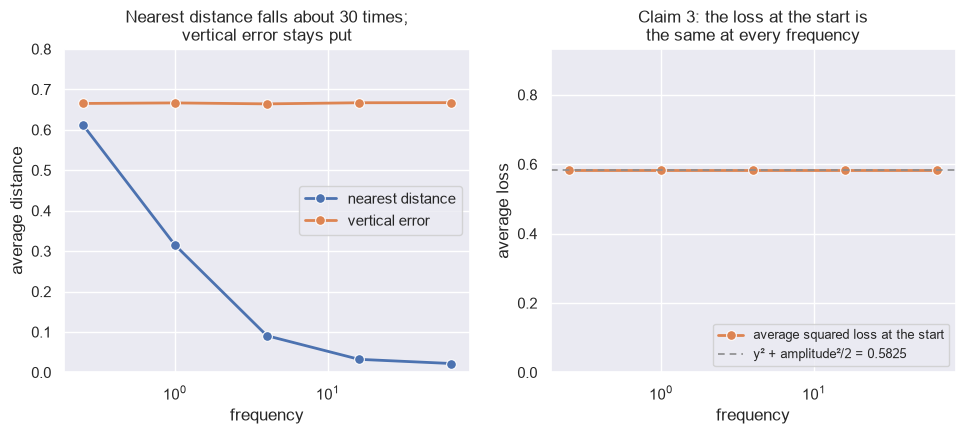

In [8]:
distance_frame = pd.concat([
    pd.DataFrame({"frequency": table_frame["frequency"], "value": table_frame["nearest"], "quantity": "nearest distance"}),
    pd.DataFrame({"frequency": table_frame["frequency"], "value": table_frame["vertical"], "quantity": "vertical error"}),
])
loss_frame = pd.DataFrame(loss_rows)

figure, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.lineplot(data=distance_frame, x="frequency", y="value", hue="quantity", marker="o", linewidth=2, markersize=7,
             palette={"nearest distance": NEAREST, "vertical error": VERTICAL}, ax=left)
left.set(xscale="log", ylim=(0, 0.8), xlabel="frequency", ylabel="average distance",
         title="Nearest distance falls about 30 times;" + chr(10) + "vertical error stays put")
left.legend(title=None, loc="center right")

sns.lineplot(data=loss_frame, x="frequency", y="average_loss", marker="o", linewidth=2, markersize=7, color=VERTICAL,
             label="average squared loss at the start", ax=right)
right.axhline(expected_loss, color=MUTED, linewidth=1.2, linestyle=(0, (4, 3)),
              label=f"y² + amplitude²/2 = {expected_loss:.4f}")
right.set(xscale="log", ylim=(0, expected_loss * 1.6), xlabel="frequency", ylabel="average loss",
          title="Claim 3: the loss at the start is" + chr(10) + "the same at every frequency")
right.legend(loc="lower right", fontsize=9)
save_figure(figure, "06-closer-but-no-better")

## Figure: with and without squiggle

Put the two ends of the table side by side: frequency 0.25 times pi (without squiggle) and 64 times pi
(with it). The loss is the average squared error on the same kind of random points, 400000 of them.
Written to `book/figures/06-with-and-without-squiggle.png`.

wrote book/figures/06-with-and-without-squiggle.png


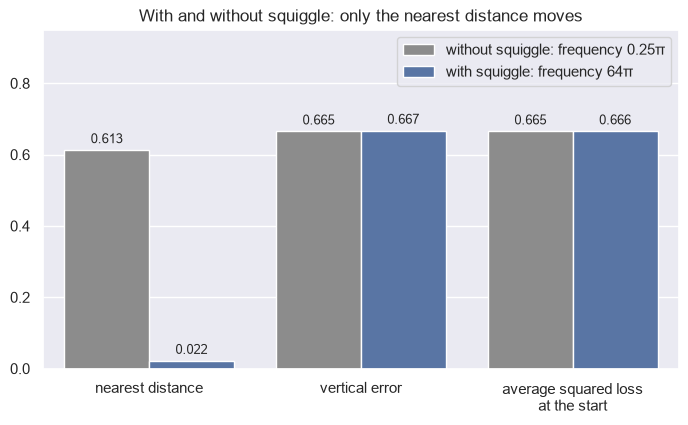

In [9]:
bars_generator = torch.Generator().manual_seed(61)
bar_sample_count = 400000
bar_x = torch.rand(bar_sample_count, generator=bars_generator) * 2 - 1
bar_y = torch.rand(bar_sample_count, generator=bars_generator) * 2 - 1
bar_phase = torch.rand(bar_sample_count, generator=bars_generator) * TWO_PI

without_row, with_row = table[0], table[-1]
bar_losses = []
for row in (without_row, with_row):
    outputs = peak * torch.sin(row["frequency"] * math.pi * bar_x + bar_phase)
    bar_losses.append(float(((bar_y - outputs) ** 2).mean()))

without_label, with_label = "without squiggle: frequency 0.25π", "with squiggle: frequency 64π"
squiggle_frame = pd.DataFrame([
    {"metric": "nearest distance", "condition": without_label, "value": without_row["nearest"]},
    {"metric": "nearest distance", "condition": with_label, "value": with_row["nearest"]},
    {"metric": "vertical error", "condition": without_label, "value": without_row["vertical"]},
    {"metric": "vertical error", "condition": with_label, "value": with_row["vertical"]},
    {"metric": "average squared loss" + chr(10) + "at the start", "condition": without_label, "value": bar_losses[0]},
    {"metric": "average squared loss" + chr(10) + "at the start", "condition": with_label, "value": bar_losses[1]},
])

figure, axis = plt.subplots(figsize=(8.2, 4.4))
sns.barplot(data=squiggle_frame, x="metric", y="value", hue="condition", palette=[BEFORE, NEAREST], ax=axis)
for container in axis.containers:
    axis.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
axis.set(ylim=(0, 0.95), xlabel="", ylabel="", title="With and without squiggle: only the nearest distance moves")
axis.legend(title=None, loc="upper right")
save_figure(figure, "06-with-and-without-squiggle")

# A model that learns

A sine with a random phase has nothing to learn. Now let the sine model train. It has `num_terms`
sines of frequency 1, 2, ..., `num_terms`, each with a learnable amplitude and phase, and it trains by
plain full-batch SGD on squared error. For sizes 1 to 64 the notebook measures:

- at the start, the average loss (the same for every size: chapter 5) and the average nearest distance
  from the data to the curve (it falls as the model grows: closer but no better);
- during training, the slope sandwich of chapter 3 at the start, the middle and the end, with the slope
  limit worked out again from the current parameters each time;
- the number of SGD steps needed to reach a fixed loss.

The speed and the final fit are measured. Nothing here is a proof.

In [10]:
SIZES = (1, 2, 4, 8, 16, 32, 64)
SEEDS = 5
STEPS = 4000
LEARNING_RATE = 0.05
TARGET_LOSS = 0.05


def make_data(data_generator, point_count=40):
    inputs = torch.rand(point_count, generator=data_generator) * TWO_PI
    labels = (0.6 * torch.sin(inputs) + 0.3 * torch.sin(3 * inputs + 1.0)
              + 0.05 * torch.randn(point_count, generator=data_generator))
    return inputs, labels


def get_loss(model, inputs, labels):
    return ((labels - model(inputs)) ** 2).mean()


def get_loss_value(model, inputs, labels):
    with torch.no_grad():
        return float(get_loss(model, inputs, labels))


def get_sandwich_slack(model, inputs, labels, sample_count=12):
    # Smallest slack of the slope sandwich over some data points, at the current parameters.
    slope_limit = model.get_slope_limit()
    lower_slack, upper_slack, nearest_values = [], [], []
    for index in range(sample_count):
        point_x, point_y = float(inputs[index]), float(labels[index])
        with torch.no_grad():
            vertical_error = abs(point_y - float(model(torch.tensor([point_x]))))
        nearest = get_nearest_distance(model, point_x, point_y, slope_limit, resolution=2e-3, include_foot=False)
        lower_slack.append(nearest - vertical_error / math.sqrt(1 + slope_limit ** 2))
        upper_slack.append(vertical_error - nearest)
        nearest_values.append(nearest)
    return min(lower_slack), min(upper_slack), sum(nearest_values) / len(nearest_values), slope_limit

## Train models of 1 to 64 terms

Five runs of each size, 4000 steps each. The slope sandwich is checked at the start, at step 2000 and at
the end of every run.

In [11]:
mean = lambda values: sum(values) / len(values)
training_rows = []
worst_lower, worst_upper = 1.0, 1.0

for num_terms in SIZES:
    initial_losses, steps_to_target, final_losses = [], [], []
    initial_nearest, final_nearest, initial_slopes, final_slopes = [], [], [], []
    for seed in range(SEEDS):
        run_generator = torch.Generator().manual_seed(100 * num_terms + seed)
        inputs, labels = make_data(run_generator)
        model = SineModel(num_terms, amplitude_scale=1.0, generator=run_generator)
        optimiser = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

        initial_losses.append(get_loss_value(model, inputs, labels))
        lower, upper, nearest, slope = get_sandwich_slack(model, inputs, labels)
        initial_nearest.append(nearest)
        initial_slopes.append(slope)
        worst_lower, worst_upper = min(worst_lower, lower), min(worst_upper, upper)

        reached = None
        for step in range(1, STEPS + 1):
            optimiser.zero_grad()
            loss = get_loss(model, inputs, labels)
            loss.backward()
            optimiser.step()
            if reached is None and loss.item() <= TARGET_LOSS:
                reached = step
            if step == STEPS // 2:
                lower, upper, _, _ = get_sandwich_slack(model, inputs, labels)
                worst_lower, worst_upper = min(worst_lower, lower), min(worst_upper, upper)
        steps_to_target.append(reached if reached is not None else STEPS + 1)
        final_losses.append(get_loss_value(model, inputs, labels))
        lower, upper, nearest, slope = get_sandwich_slack(model, inputs, labels)
        final_nearest.append(nearest)
        final_slopes.append(slope)
        worst_lower, worst_upper = min(worst_lower, lower), min(worst_upper, upper)

    training_rows.append({"num_terms": num_terms,
                          "initial_loss": mean(initial_losses), "initial_nearest": mean(initial_nearest),
                          "initial_slope_limit": mean(initial_slopes),
                          "steps_to_target": steps_to_target,
                          "median_steps_to_target": sorted(steps_to_target)[SEEDS // 2],
                          "final_loss": mean(final_losses), "final_nearest": mean(final_nearest),
                          "final_slope_limit": mean(final_slopes)})
    row = training_rows[-1]
    print(f"terms {num_terms:>3}: start loss {row['initial_loss']:.3f}, start nearest {row['initial_nearest']:.3f}, "
          f"steps to loss {TARGET_LOSS}: {steps_to_target}, final loss {row['final_loss']:.4f}")

report("the slope sandwich holds at the start, the middle and the end of training, for every size",
       worst_lower >= -SLACK and worst_upper >= -SLACK,
       f"smallest slacks {worst_lower:.1e} and {worst_upper:.1e}")
medians = [row["median_steps_to_target"] for row in training_rows]
print("median steps to loss 0.05:", medians)
start_nearest = [row["initial_nearest"] for row in training_rows]
report("closer but no better: the nearest distance at the start falls at every step up in model size",
       all(first > second for first, second in zip(start_nearest, start_nearest[1:])),
       " > ".join(f"{value:.3f}" for value in start_nearest))

terms   1: start loss 0.535, start nearest 0.609, steps to loss 0.05: [186, 224, 158, 190, 86], final loss 0.0443


terms   2: start loss 0.886, start nearest 0.514, steps to loss 0.05: [295, 99, 119, 133, 4001], final loss 0.0470


terms   4: start loss 0.420, start nearest 0.286, steps to loss 0.05: [100, 112, 69, 111, 174], final loss 0.0020


terms   8: start loss 0.564, start nearest 0.223, steps to loss 0.05: [151, 364, 338, 27, 155], final loss 0.0019


terms  16: start loss 0.839, start nearest 0.132, steps to loss 0.05: [76, 339, 48, 223, 133], final loss 0.0015


terms  32: start loss 0.669, start nearest 0.056, steps to loss 0.05: [90, 69, 35, 33, 57], final loss 0.0004


terms  64: start loss 0.645, start nearest 0.036, steps to loss 0.05: [19, 15, 20, 16, 19], final loss 0.0001
[PASS] the slope sandwich holds at the start, the middle and the end of training, for every size  (smallest slacks 1.1e-07 and -8.5e-09)
median steps to loss 0.05: [186, 133, 111, 155, 133, 57, 19]
[PASS] closer but no better: the nearest distance at the start falls at every step up in model size  (0.609 > 0.514 > 0.286 > 0.223 > 0.132 > 0.056 > 0.036)


True

## The loss at the start, over many random draws

The amplitudes are `N(0, 1 / num_terms)` and the phases are uniform, so the average loss at the start is the
mean of `y^2` plus `1/2` for every size. 300 draws of each size on one fixed data set, against that exact
expectation.

In [12]:
draw_generator = torch.Generator().manual_seed(11)
inputs, labels = make_data(draw_generator)
expected_start_loss = float((labels ** 2).mean()) + 0.5

draw_rows = []
for num_terms in SIZES:
    losses = []
    with torch.no_grad():
        for _ in range(300):
            losses.append(float(get_loss(SineModel(num_terms, generator=draw_generator), inputs, labels)))
    losses = torch.tensor(losses)
    draw_rows.append({"num_terms": num_terms, "mean_initial_loss": float(losses.mean()),
                      "standard_error": float(losses.std() / math.sqrt(len(losses))), "expected": expected_start_loss})

report("the average loss at the start is the same for every size, mean(y^2) + 1/2 (chapter 5, measured)",
       all(abs(row["mean_initial_loss"] - expected_start_loss) < 4 * row["standard_error"] for row in draw_rows),
       f"expected {expected_start_loss:.3f}; means " + ", ".join(f"{row['mean_initial_loss']:.3f}" for row in draw_rows))

[PASS] the average loss at the start is the same for every size, mean(y^2) + 1/2 (chapter 5, measured)  (expected 0.705; means 0.710, 0.700, 0.679, 0.714, 0.695, 0.693, 0.688)


True

## Figure: nearer at the start, and faster to train

Left: the nearest distance at the start falls with the number of terms while the average loss at the start
stays near 0.7 (300 draws, error bars of four standard errors). Right: the SGD steps to reach loss 0.05;
a run that did not reach it is plotted at 4000. The target is `0.6 sin(x) + 0.3 sin(3x + 1)` plus noise, so a
model with fewer than 3 terms cannot fit its third-frequency part: the best loss it can reach is about 0.045 to
0.048, right at the 0.05 threshold. The step counts for 1 and 2 terms therefore measure that floor, not the
speed of a small model. The counts for 4 terms and more are not affected, and they are not monotone below 32 terms. Written to `book/figures/06-trained-sine-model.png`.

wrote book/figures/06-trained-sine-model.png


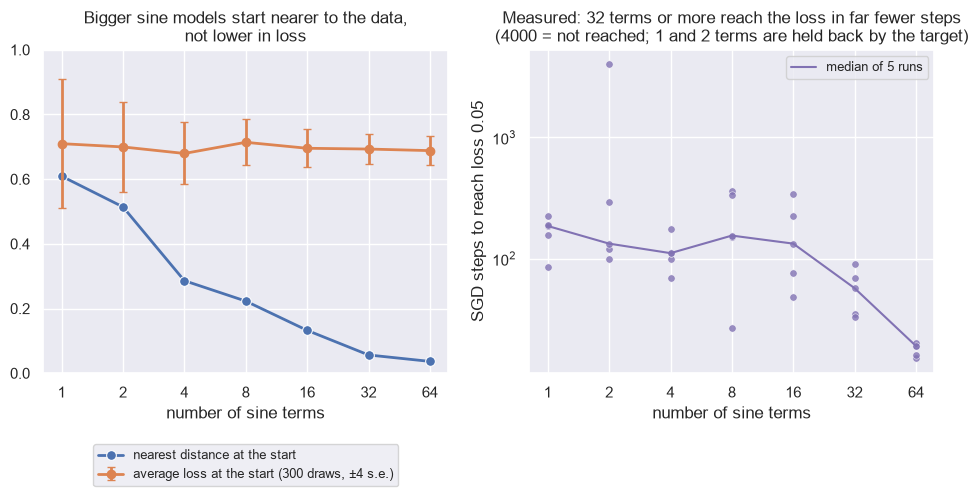

In [13]:
size_frame = pd.DataFrame(training_rows)
draw_frame = pd.DataFrame(draw_rows)
run_frame = pd.DataFrame([{"num_terms": row["num_terms"], "steps": min(step, STEPS)}
                          for row in training_rows for step in row["steps_to_target"]])

figure, (left, right) = plt.subplots(1, 2, figsize=(11.5, 4.2))
sns.lineplot(data=size_frame, x="num_terms", y="initial_nearest", marker="o", linewidth=2, markersize=7,
             color=NEAREST, label="nearest distance at the start", ax=left)
left.errorbar(draw_frame["num_terms"], draw_frame["mean_initial_loss"], yerr=4 * draw_frame["standard_error"],
              fmt="o-", color=VERTICAL, linewidth=2, capsize=3, label="average loss at the start (300 draws, ±4 s.e.)")
left.set(xscale="log", ylim=(0, 1.0), xlabel="number of sine terms", ylabel="",
         title="Bigger sine models start nearer to the data," + chr(10) + "not lower in loss")
left.set_xticks(list(SIZES), [str(size) for size in SIZES])
left.minorticks_off()
left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)

sns.scatterplot(data=run_frame, x="num_terms", y="steps", color=MODEL, s=28, alpha=0.8, legend=False, ax=right)
sns.lineplot(data=size_frame, x="num_terms", y="median_steps_to_target", color=MODEL, linewidth=1.5,
             label="median of 5 runs", ax=right)
right.set(xscale="log", yscale="log", xlabel="number of sine terms", ylabel="SGD steps to reach loss 0.05",
          title="Measured: 32 terms or more reach the loss in far fewer steps" + chr(10) + "(4000 = not reached; 1 and 2 terms are held back by the target)")
right.set_xticks(list(SIZES), [str(size) for size in SIZES])
right.minorticks_off()
right.legend(loc="upper right", fontsize=9)
save_figure(figure, "06-trained-sine-model")

## Figure: before and after training

The nearest distance and the average squared loss, before training and after 4000 steps, for sizes 1 to 64
(mean of 5 runs, log scale). Written to `book/figures/06-before-and-after-training.png`.

wrote book/figures/06-before-and-after-training.png


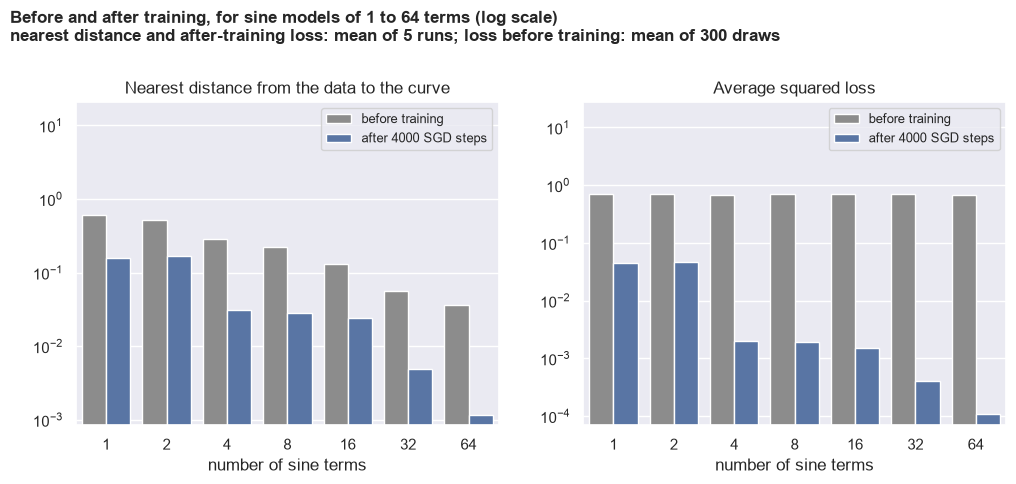

In [14]:
long_frame = pd.concat([
    pd.DataFrame({"terms": size_frame["num_terms"].astype(str), "when": "before training",
                  "nearest": size_frame["initial_nearest"], "loss": draw_frame["mean_initial_loss"]}),
    pd.DataFrame({"terms": size_frame["num_terms"].astype(str), "when": "after 4000 SGD steps",
                  "nearest": size_frame["final_nearest"], "loss": size_frame["final_loss"]}),
])

figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
for axis, column, title in ((left, "nearest", "Nearest distance from the data to the curve"),
                            (right, "loss", "Average squared loss")):
    sns.barplot(data=long_frame, x="terms", y=column, hue="when", palette=[BEFORE, NEAREST], ax=axis)
    axis.set(yscale="log", xlabel="number of sine terms", ylabel="", title=title)
    axis.set_ylim(top=axis.get_ylim()[1] * 25)          # room above the bars for the legend
    axis.legend(title=None, loc="upper right", fontsize=9)
figure.suptitle("Before and after training, for sine models of 1 to 64 terms (log scale)" + chr(10) +
                "nearest distance and after-training loss: mean of 5 runs; loss before training: mean of 300 draws",
                y=1.1, x=0.07, ha="left", fontsize=12, fontweight="bold")
save_figure(figure, "06-before-and-after-training")